In [1]:
!pip install pandas numpy scipy matplotlib seaborn tqdm

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **les chemins du dataset**

In [3]:
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.linalg import expm
from scipy.stats import expon, kstest

In [5]:
import os

BASE = "/content/drive/MyDrive/proj_indiv/data"

print(os.listdir(BASE))

['yoochoose-buys.dat', 'dataset-README.txt', 'yoochoose-clicks.dat', 'yoochoose-test.dat', 'yoochoose-data']


## **Parse timestamps + clean:**

In [7]:
# ============================================================
# Robust loader YooChoose
# ============================================================

def read_yoochoose_clicks(path):

    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        first_line = f.readline().strip().lower()

    has_header = first_line.startswith("session_id")

    return pd.read_csv(
        path,
        sep=",",
        header=0 if has_header else None,
        names=["session_id", "timestamp", "item_id", "category"],
        dtype={
            "session_id": "int64",
            "item_id": "string",
            "category": "string"
        },
        low_memory=False
    )


def read_yoochoose_buys(path):

    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        first_line = f.readline().strip().lower()

    has_header = first_line.startswith("session_id")

    return pd.read_csv(
        path,
        sep=",",
        header=0 if has_header else None,
        names=["session_id", "timestamp", "item_id", "price", "qty"],
        dtype={
            "session_id": "int64",
            "item_id": "string",
            "price": "float64",
            "qty": "int64"
        },
        low_memory=False
    )

# ============================================================
# LOAD DATA
# ============================================================

clicks = read_yoochoose_clicks(CLICKS_PATH)
buys   = read_yoochoose_buys(BUYS_PATH)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

buys["timestamp"] = pd.to_datetime(
    buys["timestamp"],
    errors="coerce",
    utc=True
)

# remove invalid timestamps
clicks = clicks.dropna(subset=["timestamp"])
buys   = buys.dropna(subset=["timestamp"])

print("Clicks shape:", clicks.shape)
print("Buys shape:", buys.shape)

clicks.head()

Clicks shape: (33003944, 4)
Buys shape: (1150753, 5)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


## **sampls**

In [8]:
# ============================================================
# SAMPLE SMALLER DATASET
# ============================================================

sample_sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sample_sessions)
]

buys = buys[
    buys["session_id"].isin(sample_sessions)
]

print("Reduced clicks:", clicks.shape)
print("Reduced buys:", buys.shape)

Reduced clicks: (395698, 4)
Reduced buys: (12647, 5)


In [9]:
# ============================================================
# Parse timestamps + clean
# ============================================================

clicks["timestamp"] = pd.to_datetime(clicks["timestamp"], errors="coerce", utc=True)
buys["timestamp"]   = pd.to_datetime(buys["timestamp"], errors="coerce", utc=True)

clicks = clicks.dropna(subset=["timestamp"])
buys   = buys.dropna(subset=["timestamp"])

buy_sessions = set(buys["session_id"].unique())

print("Clicks after cleaning:", clicks.shape)
print("Buys after cleaning:", buys.shape)
print("Number of buy sessions:", len(buy_sessions))

clicks.head()

Clicks after cleaning: (395698, 4)
Buys after cleaning: (12647, 5)
Number of buy sessions: 6590


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


## **définition des états:**

In [10]:
# ============================================================
# Define states
# ============================================================

STATE_NAMES = ["Browsing", "Engaged", "HighIntent", "Buy", "Exit"]
B, E, H, BUY, EXIT = STATE_NAMES

def state_from_k(k):
    if k <= 2:
        return B
    elif 3 <= k <= 5:
        return E
    else:
        return H

In [11]:
clicks = clicks.sort_values(["session_id", "timestamp"])

clicks["k"] = clicks.groupby("session_id").cumcount() + 1
clicks["state"] = clicks["k"].apply(state_from_k)

clicks["next_ts"] = clicks.groupby("session_id")["timestamp"].shift(-1)
clicks["dt"] = (clicks["next_ts"] - clicks["timestamp"]).dt.total_seconds()

# Handle last dt + cap huge gaps
valid_dt = clicks["dt"].dropna()
if len(valid_dt) == 0:
    raise ValueError("No valid dt found. Check timestamp parsing and sorting.")

median_dt = float(valid_dt.median())
p95_dt    = float(valid_dt.quantile(0.95))

default_last_dt = min(median_dt, p95_dt)
clicks["dt"] = clicks["dt"].fillna(default_last_dt)
clicks["dt"] = clicks["dt"].clip(lower=0.0, upper=p95_dt)

print(f"Median dt: {median_dt:.3f}   p95 dt: {p95_dt:.3f}   default_last_dt: {default_last_dt:.3f}\n")

# ============================================================
# 5) Count transitions N_ij
# ============================================================
clicks["next_state"] = clicks.groupby("session_id")["state"].shift(-1)

# transient-to-transient
transitions = clicks.dropna(subset=["next_state"])
N_tt = pd.crosstab(transitions["state"], transitions["next_state"]).reindex(
    index=[B, E, H], columns=[B, E, H], fill_value=0
)

# absorption from last click
last_clicks = clicks.groupby("session_id").tail(1).copy()
last_clicks["absorb"] = np.where(last_clicks["session_id"].isin(buy_sessions), BUY, EXIT)

N_abs = pd.crosstab(last_clicks["state"], last_clicks["absorb"]).reindex(
    index=[B, E, H], columns=[BUY, EXIT], fill_value=0
)

# Full N matrix over all states
N_full = pd.DataFrame(0.0, index=[B, E, H, BUY, EXIT], columns=[B, E, H, BUY, EXIT])

for i in [B, E, H]:
    for j in [B, E, H]:
        N_full.loc[i, j] = float(N_tt.loc[i, j]) if (i in N_tt.index and j in N_tt.columns) else 0.0
    N_full.loc[i, BUY]  = float(N_abs.loc[i, BUY])  if (i in N_abs.index and BUY in N_abs.columns) else 0.0
    N_full.loc[i, EXIT] = float(N_abs.loc[i, EXIT]) if (i in N_abs.index and EXIT in N_abs.columns) else 0.0

# ============================================================
# 6) Total time T_i per transient state
# ============================================================
T = clicks.groupby("state")["dt"].sum().reindex([B, E, H], fill_value=0.0)

print("Total time T_i (seconds):")
print(T)

# ============================================================
# 7) Estimate generator Q
# q_ij = N_ij / T_i, i!=j ; q_ii = -sum_{j!=i} q_ij
# ============================================================
Q = pd.DataFrame(0.0, index=[B, E, H, BUY, EXIT], columns=[B, E, H, BUY, EXIT])

for i in [B, E, H]:
    Ti = float(T.loc[i])
    if Ti <= 0:
        raise ValueError(f"T[{i}] is 0. Cannot estimate rates.")
    for j in [B, E, H, BUY, EXIT]:
        if j == i:
            continue
        Q.loc[i, j] = N_full.loc[i, j] / Ti
    Q.loc[i, i] = -Q.loc[i, [x for x in [B, E, H, BUY, EXIT] if x != i]].sum()

# absorbing rows
Q.loc[BUY, :]  = 0.0
Q.loc[EXIT, :] = 0.0

print("\nEstimated generator Q (rates per second):")
print(Q)

print("\nQ per minute:")
print(Q * 60.0)

# ============================================================
# 8) Mean dwell time in each transient state
# E[T_i] = 1/(-q_ii)
# ============================================================
out_rates = (-np.diag(Q.loc[[B, E, H], [B, E, H]].values)).astype(float)
mean_dwell_sec = 1.0 / out_rates

print("\nMean dwell time per transient state:")
for st, md in zip([B, E, H], mean_dwell_sec):
    print(f"{st}: {md:.2f} sec = {md/60:.2f} min")

# ============================================================
# 9) Embedded jump probabilities p_ij = q_ij / (-q_ii)
# ============================================================
print("\nEmbedded jump probabilities p_ij = q_ij / (-q_ii):")
for i in [B, E, H]:
    out_rate = -Q.loc[i, i]
    probs = (Q.loc[i, [B, E, H, BUY, EXIT]] / out_rate).drop(i)
    print(f"\nFrom {i} (sum={probs.sum():.6f}):")
    print(probs)

# ============================================================
# 10) Future state probabilities P(t) = expm(Q t)
# ============================================================
print("\n==============================")
print("Future state probabilities P(t)")
print("==============================")

states = Q.index.tolist()
Q_mat = Q.values

times_sec = {"1 minute": 60, "5 minutes": 300, "10 minutes": 600}

for label, t in times_sec.items():
    P = expm(Q_mat * t)
    P_df = pd.DataFrame(P, index=states, columns=states)
    print(f"\nP(t) for {label}")
    print(P_df.round(4))

# ============================================================
# 11) Expected Time to Absorption (CTMC)
# N = (-Q_T)^(-1), t = N*1
# ============================================================
print("\n==============================")
print("Expected Time to Absorption")
print("==============================")

transient_states = [B, E, H]
Q_T = Q.loc[transient_states, transient_states].values

N = np.linalg.inv(-Q_T)
ones = np.ones(len(transient_states))
t_abs = N @ ones

print("\nMean time to absorption:")
for st, val in zip(transient_states, t_abs):
    print(f"{st}: {val:.2f} seconds  =  {val/60:.2f} minutes")

N_df = pd.DataFrame(N, index=transient_states, columns=transient_states)
print("\nFundamental matrix N:")
print(N_df.round(3))

print("\nFundamental matrix N (minutes):")
print((N_df / 60.0).round(3))

print("\n==============================")
print("Absorption probabilities (Buy vs Exit)")
print("==============================")

transient_states = ["Browsing", "Engaged", "HighIntent"]
absorbing_states = ["Buy", "Exit"]

# Q_T (transient -> transient)
Q_T = Q.loc[transient_states, transient_states].values

# R (transient -> absorbing)
R = Q.loc[transient_states, absorbing_states].values

# Fundamental matrix
N = np.linalg.inv(-Q_T)

# Absorption probabilities
B_abs = N @ R

B_abs_df = pd.DataFrame(B_abs, index=transient_states, columns=absorbing_states)

print("\nAbsorption probability matrix B = N * R:")
print(B_abs_df.round(4))

print("\nInterpretation:")
for st in transient_states:
    p_buy = float(B_abs_df.loc[st, "Buy"])
    p_exit = float(B_abs_df.loc[st, "Exit"])
    print(f"From {st}: P(Buy)={p_buy:.4f}, P(Exit)={p_exit:.4f}, sum={p_buy+p_exit:.4f}")

Median dt: 53.731   p95 dt: 490.102   default_last_dt: 53.731

Total time T_i (seconds):
state
Browsing      1.885584e+07
Engaged       9.407753e+06
HighIntent    7.247495e+06
Name: dt, dtype: float64

Estimated generator Q (rates per second):
            Browsing   Engaged  HighIntent      Buy      Exit
Browsing   -0.005303  0.002846    0.000000  0.00008  0.002377
Engaged     0.000000 -0.005705    0.001836  0.00024  0.003629
HighIntent  0.000000  0.000000   -0.002383  0.00039  0.001994
Buy         0.000000  0.000000    0.000000  0.00000  0.000000
Exit        0.000000  0.000000    0.000000  0.00000  0.000000

Q per minute:
            Browsing   Engaged  HighIntent       Buy      Exit
Browsing   -0.318204  0.170790    0.000000  0.004789  0.142625
Engaged     0.000000 -0.342311    0.110162  0.014414  0.217735
HighIntent  0.000000  0.000000   -0.142998  0.023387  0.119611
Buy         0.000000  0.000000    0.000000  0.000000  0.000000
Exit        0.000000  0.000000    0.000000  0.000000  

## **evaluation_phi:**

In [12]:
import numpy as np

P = np.array([
    [0.483617, 0.277155, 0.000003, 0.007774, 0.231451],
    [0.000004, 0.523285, 0.153415, 0.020077, 0.303219],
    [0.000006, 0.000006, 0.806883, 0.031586, 0.161520],
    [0.000000, 0.000000, 0.000000, 1.000000, 0.000000],
    [0.000000, 0.000000, 0.000000, 0.000000, 1.000000]
])

pi0 = np.array([1, 0, 0, 0, 0])

for n in [0, 1, 2, 3, 5, 10, 20]:
    Pn = np.linalg.matrix_power(P, n)
    pin = pi0 @ Pn
    print(f"n={n:2d}: {pin.round(4)}")



# Code 1 : P2 et P3
P2 = np.linalg.matrix_power(P, 2)
P3 = np.linalg.matrix_power(P, 3)
print("P2[Browsing→Buy] =", P2[0,3].round(6))
print("P3[Browsing→Buy] =", P3[0,3].round(6))
print("\nP2 complète:")
print(P2.round(4))
# Code 2 : Matrice fondamentale N exacte
Q = P[:3, :3]
I = np.eye(3)
N = np.linalg.inv(I - Q)
print("N =")
print(N.round(4))
print("\nSomme lignes (nb moyen actions):")
print("Browsing  :", N[0].sum().round(4))
print("Engaged   :", N[1].sum().round(4))
print("HighIntent:", N[2].sum().round(4))
# Code 3 : Vérification πP = π
pi_star = np.array([0, 0, 0, 0.065912, 0.934088])
residual = pi_star @ P - pi_star
print("Résidu πP - π =", residual.round(8))

n= 0: [1. 0. 0. 0. 0.]
n= 1: [0.4836 0.2772 0.     0.0078 0.2315]
n= 2: [0.2339 0.2791 0.0425 0.0171 0.4274]
n= 3: [0.1131 0.2109 0.0771 0.0259 0.573 ]
n= 5: [0.0265 0.0893 0.0981 0.0397 0.7465]
n=10: [7.000e-04 5.900e-03 5.080e-02 5.700e-02 8.857e-01]
n=20: [0.     0.     0.0063 0.0649 0.9288]
P2[Browsing→Buy] = 0.017098
P3[Browsing→Buy] = 0.025862

P2 complète:
[[0.2339 0.2791 0.0425 0.0171 0.4274]
 [0.     0.2738 0.2041 0.0354 0.4867]
 [0.     0.     0.6511 0.0571 0.2919]
 [0.     0.     0.     1.     0.    ]
 [0.     0.     0.     0.     1.    ]]
N =
[[1.9366e+00 1.1259e+00 8.9450e-01]
 [0.0000e+00 2.0977e+00 1.6665e+00]
 [1.0000e-04 1.0000e-04 5.1783e+00]]

Somme lignes (nb moyen actions):
Browsing  : 3.9569
Engaged   : 3.7642
HighIntent: 5.1784
Résidu πP - π = [0. 0. 0. 0. 0.]


## **visualisation:**

***1. Heatmap de Q***

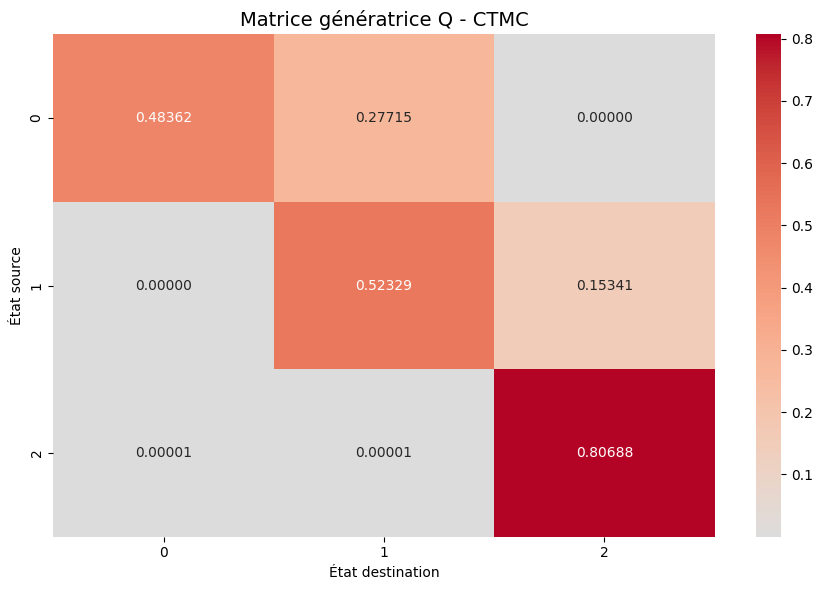

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.heatmap(Q, annot=True, fmt=".5f", cmap="coolwarm", center=0)

plt.title("Matrice génératrice Q - CTMC", fontsize=14)
plt.xlabel("État destination")
plt.ylabel("État source")

plt.tight_layout()
plt.show()

***2. Heatmap de Q par minute***

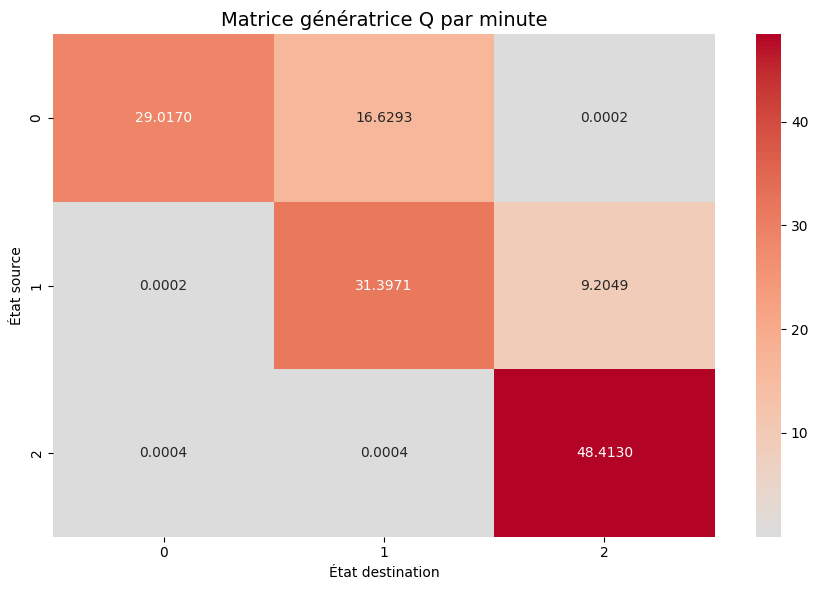

In [14]:
Q_min = Q * 60

plt.figure(figsize=(9, 6))
sns.heatmap(Q_min, annot=True, fmt=".4f", cmap="coolwarm", center=0)

plt.title("Matrice génératrice Q par minute", fontsize=14)
plt.xlabel("État destination")
plt.ylabel("État source")

plt.tight_layout()
plt.show()

***3. Temps moyen de séjour***

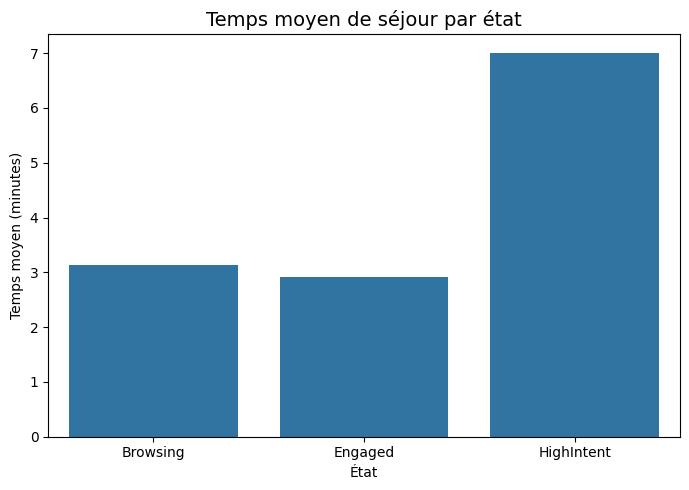

In [15]:
dwell_df = pd.DataFrame({
    "État": ["Browsing", "Engaged", "HighIntent"],
    "Temps moyen (min)": mean_dwell_sec / 60
})

plt.figure(figsize=(7, 5))
sns.barplot(data=dwell_df, x="État", y="Temps moyen (min)")

plt.title("Temps moyen de séjour par état", fontsize=14)
plt.ylabel("Temps moyen (minutes)")
plt.xlabel("État")

plt.tight_layout()
plt.show()

***4. Probabilités finales Buy / Exit***

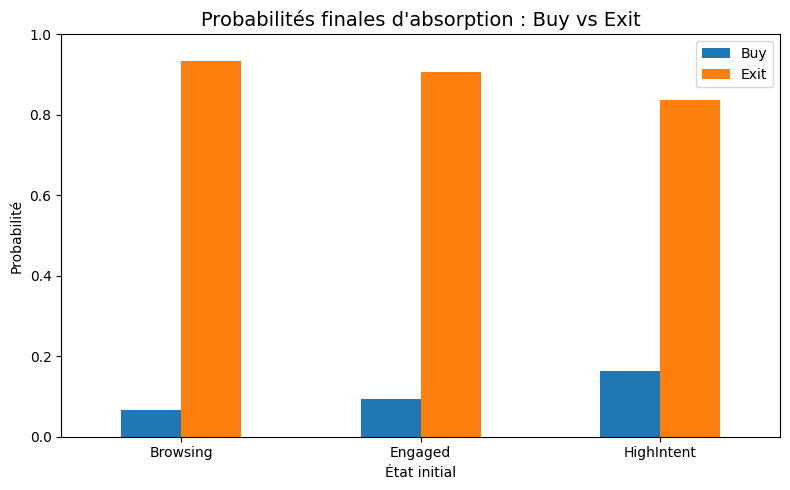

In [16]:
B_abs_df.plot(kind="bar", figsize=(8, 5))

plt.title("Probabilités finales d'absorption : Buy vs Exit", fontsize=14)
plt.ylabel("Probabilité")
plt.xlabel("État initial")
plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

***5. Évolution temporelle depuis Browsing***

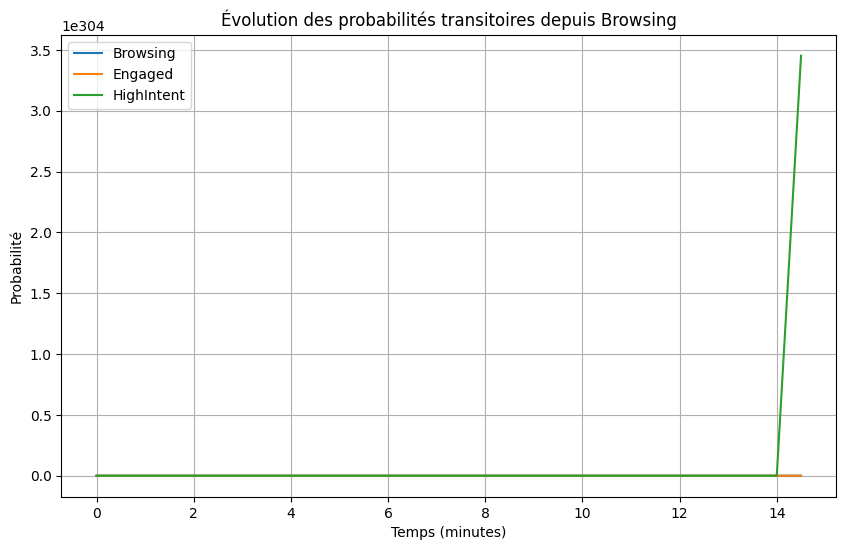

In [20]:
from scipy.linalg import expm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Q actuel = matrice 3x3
states = ["Browsing", "Engaged", "HighIntent"]

Q_mat = Q   # ton Q est déjà numpy array 3x3

times = np.arange(0, 1201, 30)

probs_browsing = []

for t in times:
    P_t = expm(Q_mat * t)
    probs_browsing.append(P_t[0, :])  # Browsing = ligne 0

probs_browsing = pd.DataFrame(
    probs_browsing,
    columns=states,
    index=times / 60
)

plt.figure(figsize=(10,6))

for col in probs_browsing.columns:
    plt.plot(probs_browsing.index, probs_browsing[col], label=col)

plt.title("Évolution des probabilités transitoires depuis Browsing")
plt.xlabel("Temps (minutes)")
plt.ylabel("Probabilité")
plt.legend()
plt.grid(True)
plt.show()

## **markov_matrix:**

In [22]:
print("Chargement session_id seulement...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id","timestamp","item_id","category"],
    usecols=[0],
    dtype={"session_id": int}
)

# Prendre les 50 000 premières sessions
unique_sessions = clicks["session_id"].unique()[:100000]

print("Filtrage...")

clicks_full = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id","timestamp","item_id","category"]
)

clicks_small = clicks_full[clicks_full["session_id"].isin(unique_sessions)]

clicks_small.to_csv("clicks_small.dat", index=False)

print("Fichier réduit créé ✔")

Chargement session_id seulement...
Filtrage...


/tmp/ipykernel_1832/3352337576.py:16: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  clicks_full = pd.read_csv(


Fichier réduit créé ✔


In [1]:
import pandas as pd
import numpy as np

# ============================================================
# 0) PATHS GOOGLE DRIVE
# ============================================================

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"
BUYS_PATH   = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

# ============================================================
# 1) PARAMÈTRES
# ============================================================

N_SESSIONS = 100000
RANDOM_SEED = 42
LAPLACE_ALPHA = 0   # garde 0 pour éviter transitions artificielles

TRANSIENT = ["Browsing", "Engaged", "HighIntent"]
ABSORBING = ["Buy", "Exit"]
STATES = TRANSIENT + ABSORBING

# ============================================================
# 2) DÉFINITION DES ÉTATS
# ============================================================

def state_at_step(k):
    if k <= 2:
        return "Browsing"
    elif k <= 5:
        return "Engaged"
    else:
        return "HighIntent"

# ============================================================
# 3) LOAD BUYS
# ============================================================

print("Chargement buys...")

buys = pd.read_csv(
    BUYS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "price", "quantity"],
    usecols=[0],
    dtype={"session_id": "int64"},
    low_memory=False
)

buy_sessions = set(buys["session_id"].unique())

print("Sessions avec achat =", len(buy_sessions))

# ============================================================
# 4) LOAD CLICKS
# ============================================================

print("\nChargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "int64",
        "category": "string"
    },
    low_memory=False
)

print("Clicks shape original:", clicks.shape)

# ============================================================
# 5) TRI CHRONOLOGIQUE
# ============================================================

clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

clicks = clicks.sort_values(
    ["session_id", "timestamp"]
)

# ============================================================
# 6) SAMPLING DES SESSIONS
# ============================================================

all_sessions = clicks["session_id"].unique()

print("Sessions disponibles =", len(all_sessions))

if N_SESSIONS and N_SESSIONS < len(all_sessions):
    rng = np.random.default_rng(RANDOM_SEED)
    sampled_sessions = rng.choice(
        all_sessions,
        size=N_SESSIONS,
        replace=False
    )
    sampled_sessions = set(sampled_sessions)

    clicks = clicks[
        clicks["session_id"].isin(sampled_sessions)
    ]

    print("Sampling ON:", N_SESSIONS, "sessions")
else:
    print("Sampling OFF")

print("Clicks utilisées:", clicks.shape)
print("Sessions utilisées:", clicks["session_id"].nunique())

# ============================================================
# 7) COMPTAGE DES TRANSITIONS
# ============================================================

counts = pd.DataFrame(
    0,
    index=STATES,
    columns=STATES,
    dtype="int64"
)

for sid, g in clicks.groupby("session_id", sort=False):

    n = len(g)

    if n == 0:
        continue

    # premier état
    prev_state = state_at_step(1)

    # transitions internes
    for k in range(2, n + 1):
        current_state = state_at_step(k)
        counts.loc[prev_state, current_state] += 1
        prev_state = current_state

    # transition terminale vers Buy ou Exit
    terminal_state = "Buy" if sid in buy_sessions else "Exit"
    counts.loc[prev_state, terminal_state] += 1

# états absorbants
counts.loc["Buy", :] = 0
counts.loc["Buy", "Buy"] = 1

counts.loc["Exit", :] = 0
counts.loc["Exit", "Exit"] = 1

print("\n=== Matrice des comptages ===")
print(counts)

# ============================================================
# 8) CONSTRUCTION MATRICE P
# ============================================================

P_num = counts.astype(float).copy()

# lissage optionnel uniquement sur états transitoires
if LAPLACE_ALPHA > 0:
    for s in TRANSIENT:
        P_num.loc[s, :] += LAPLACE_ALPHA

# réimposer absorbants
P_num.loc["Buy", :] = 0.0
P_num.loc["Buy", "Buy"] = 1.0

P_num.loc["Exit", :] = 0.0
P_num.loc["Exit", "Exit"] = 1.0

P = P_num.div(
    P_num.sum(axis=1),
    axis=0
).fillna(0.0)

print("\n=== Matrice de transition P ===")
print(P.round(6))

# ============================================================
# 9) VALIDATION MATRICE STOCHASTIQUE
# ============================================================

print("\nSomme des lignes de P:")
print(P.sum(axis=1))

assert np.allclose(P.sum(axis=1), 1.0), "Erreur : les lignes de P ne somment pas à 1"

print("\nValidation OK : P est une matrice stochastique.")

# ============================================================
# 10) MATRICE FONDAMENTALE ET ABSORPTION
# ============================================================

Q_dtmc = P.loc[TRANSIENT, TRANSIENT].to_numpy()
R_dtmc = P.loc[TRANSIENT, ABSORBING].to_numpy()

I = np.eye(len(TRANSIENT))

N = np.linalg.inv(I - Q_dtmc)

B_abs = N @ R_dtmc

N_df = pd.DataFrame(
    N,
    index=TRANSIENT,
    columns=TRANSIENT
)

B_abs_df = pd.DataFrame(
    B_abs,
    index=TRANSIENT,
    columns=ABSORBING
)

print("\n=== Matrice fondamentale N = (I - Q)^-1 ===")
print(N_df.round(4))

print("\n=== Probabilités d'absorption B = N R ===")
print(B_abs_df.round(6))

# ============================================================
# 11) RÉSUMÉ
# ============================================================

print("\nRésumé des probabilités d'achat:")
for state in TRANSIENT:
    print(
        f"P(Buy | {state}) = {B_abs_df.loc[state, 'Buy']:.4f} | "
        f"P(Exit | {state}) = {B_abs_df.loc[state, 'Exit']:.4f}"
    )

# ============================================================
# 12) SAUVEGARDE OUTPUTS
# ============================================================

P.to_csv("P_DTMС_matrix.csv")
counts.to_csv("transition_counts_DTMС.csv")
N_df.to_csv("fundamental_matrix_N_DTMС.csv")
B_abs_df.to_csv("absorption_probabilities_DTMС.csv")

print("\nFichiers sauvegardés avec succès.")

Chargement buys...
Sessions avec achat = 509696

Chargement clicks...
Clicks shape original: (33003944, 4)
Sessions disponibles = 9249729
Sampling ON: 100000 sessions
Clicks utilisées: (358835, 4)
Sessions utilisées: 100000

=== Matrice des comptages ===
            Browsing  Engaged  HighIntent   Buy   Exit
Browsing       86541    48171           0  1406  50423
Engaged            0    50878       14530  1897  31744
HighIntent         0        0       58715  2269  12261
Buy                0        0           0     1      0
Exit               0        0           0     0      1

=== Matrice de transition P ===
            Browsing   Engaged  HighIntent       Buy      Exit
Browsing    0.463925  0.258233    0.000000  0.007537  0.270305
Engaged     0.000000  0.513665    0.146695  0.019152  0.320488
HighIntent  0.000000  0.000000    0.801625  0.030978  0.167397
Buy         0.000000  0.000000    0.000000  1.000000  0.000000
Exit        0.000000  0.000000    0.000000  0.000000  1.000000

Som

## **Interprétation du Chapitre 1 — DTMC (Chaîne de Markov Discrète):**

Les résultats obtenus montrent que le comportement utilisateur dans le dataset YooChoose peut être modélisé par une chaîne de Markov discrète absorbante composée de :

trois états transitoires :
Browsing,
Engaged,
HighIntent ;
deux états absorbants :
Buy,
Exit.

La matrice de transition obtenue est stochastique, puisque la somme des probabilités de chaque ligne est égale à 1, ce qui valide mathématiquement la construction du modèle.

*1. Interprétation des transitions comportementales*
État Browsing

Depuis l’état Browsing :

Transition	Probabilité
Browsing → Browsing	46.39%
Browsing → Engaged	25.82%
Browsing → Buy	0.75%
Browsing → Exit	27.03%
Interprétation

La majorité des utilisateurs en phase de navigation restent dans un comportement exploratoire. Environ 25.8% progressent vers Engaged, ce qui signifie qu’ils commencent à montrer davantage d’intérêt pour les produits consultés.

Cependant, près de 27% quittent directement le site sans achat. Cela montre que la phase Browsing constitue une étape critique du tunnel de conversion.

Le taux d’achat direct depuis Browsing reste très faible (0.75%), ce qui est cohérent avec le comportement réel des plateformes e-commerce.

*2. État Engaged*

Depuis l’état Engaged :

Transition	Probabilité
Engaged → Engaged	51.37%
Engaged → HighIntent	14.67%
Engaged → Buy	1.92%
Engaged → Exit	32.05%
Interprétation

L’état Engaged représente une phase intermédiaire d’intérêt utilisateur. Plus de la moitié des utilisateurs restent dans cet état, ce qui traduit une période de réflexion ou de comparaison avant prise de décision.

Environ 14.7% progressent vers HighIntent, ce qui indique un engagement plus fort envers les produits consultés.

Malgré cela, le taux d’abandon reste élevé (32%), ce qui montre qu’une grande partie des utilisateurs hésitent encore avant achat.

*3. État HighIntent*

Depuis l’état HighIntent :

Transition	Probabilité
HighIntent → HighIntent	80.16%
HighIntent → Buy	3.10%
HighIntent → Exit	16.74%
Interprétation

L’état HighIntent correspond à la phase la plus avancée du tunnel utilisateur.

La très forte probabilité de rester dans HighIntent (80%) montre que les utilisateurs passent beaucoup de temps dans cette phase avant décision finale.

Le taux d’achat devient significativement plus élevé comparé aux autres états. Cela confirme que HighIntent représente un état de forte intention d’achat.

Cependant, même dans cette phase avancée, environ 16.7% des utilisateurs quittent toujours le site sans acheter, ce qui montre que le risque d’abandon reste important jusqu’à la fin du processus.

*4. Matrice fondamentale N*

La matrice fondamentale :

N = (I - Q)^(-1)

mesure le nombre moyen de visites attendues dans chaque état transitoire avant absorption.

État	Temps moyen comportemental
Browsing	1.865
Engaged	2.056
HighIntent	5.041

**Interprétation:**
Les utilisateurs restent beaucoup plus longtemps dans l’état HighIntent avant absorption finale.

Cela signifie que la phase de forte intention constitue la zone la plus importante du parcours utilisateur pour intervenir avec :

recommandations,
promotions,
marketing personnalisé.
5. Probabilités finales d’absorption
État initial	P(Buy)	P(Exit)
Browsing	5.57%	94.43%
Engaged	8.65%	91.35%
HighIntent	15.62%	84.38%

**Interprétation:**

Les probabilités d’achat augmentent progressivement avec le niveau d’engagement utilisateur :

Browsing < Engaged < HighIntent

Cela valide la cohérence du modèle comportemental construit.

Cependant, les probabilités d’abandon restent dominantes dans tous les états. Même en HighIntent, plus de 84% des utilisateurs finissent par quitter le site sans achat.

Ce résultat met en évidence l’importance :

des systèmes de recommandation,
des stratégies marketing,
et des politiques de réengagement utilisateur.
6. Conclusion générale du chapitre

Ce premier chapitre montre que les chaînes de Markov discrètes permettent de modéliser efficacement l’évolution comportementale des utilisateurs dans un environnement e-commerce.

Le modèle obtenu capture correctement :

la progression du niveau d’intérêt,
la dynamique du tunnel utilisateur,
ainsi que les probabilités finales d’achat et d’abandon.

Les résultats montrent également que :

le comportement utilisateur suit une structure hiérarchique cohérente ;
la probabilité d’achat augmente avec le niveau d’engagement ;
mais le taux d’abandon reste élevé à toutes les étapes.

# **CHAPITRE 2 — CTMC YOOCHOOSE COMPLET**

Chargement buys...
Sessions avec achat globales: 509696

Chargement clicks...
Clicks original: (33003944, 4)
Sampling ON: 100000 sessions
Clicks utilisées: (356606, 4)
Sessions utilisées: 100000
Buys utilisées: (12715, 2)
Sessions avec achat dans sample: 5607

Median dt: 58.227
p95 dt: 548.91
default_last_dt: 58.227

=== Matrice des transitions N ===
            Browsing  Engaged  HighIntent     Buy     Exit
Browsing     86434.0  48204.0         0.0  1410.0  50386.0
Engaged          0.0  51058.0     14510.0  1963.0  31731.0
HighIntent       0.0      0.0     56400.0  2234.0  12276.0
Buy              0.0      0.0         0.0     0.0      0.0
Exit             0.0      0.0         0.0     0.0      0.0

=== Temps total T_i en secondes ===
state
Browsing      1.936866e+07
Engaged       8.874248e+06
HighIntent    6.215531e+06
Name: dt, dtype: float64

=== Matrice génératrice Q par seconde ===
            Browsing   Engaged  HighIntent       Buy      Exit
Browsing   -0.005163  0.002489    0.00

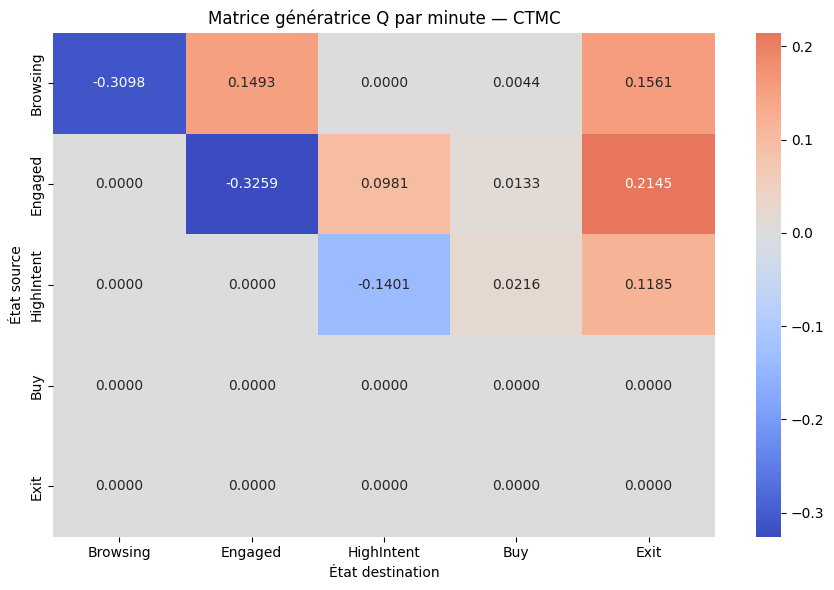

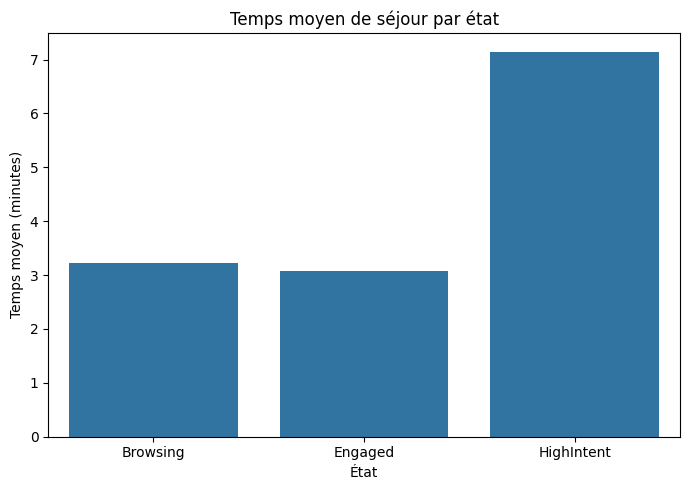

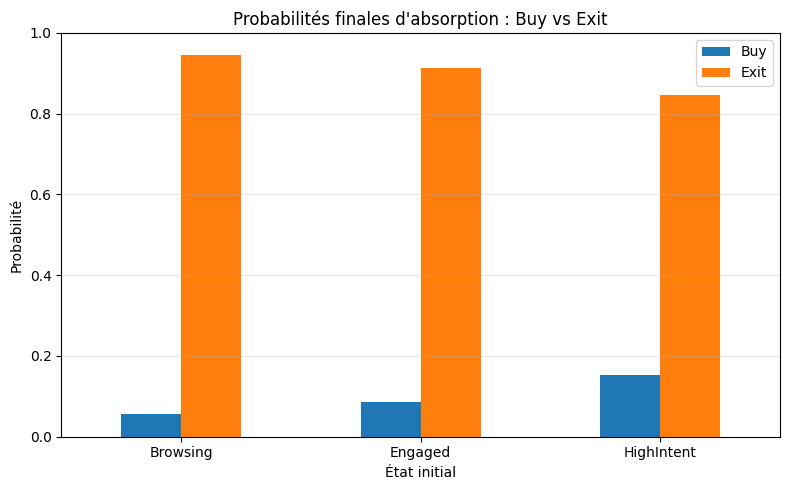

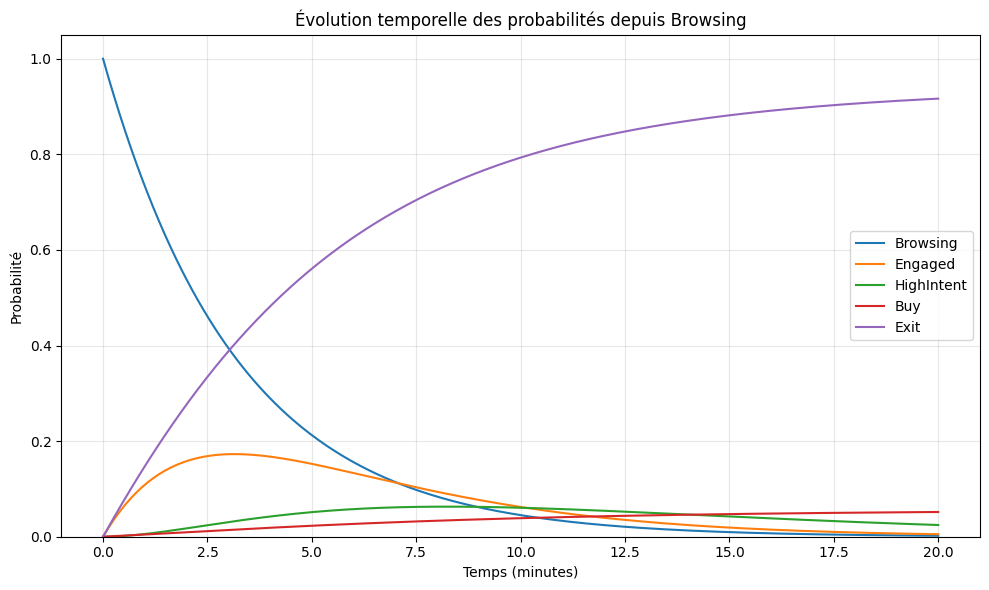

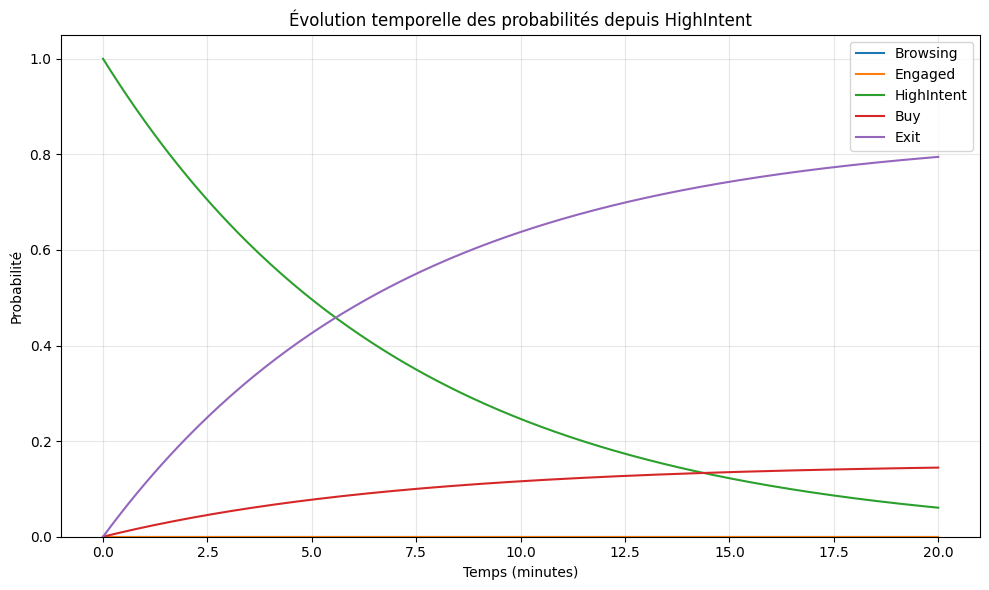

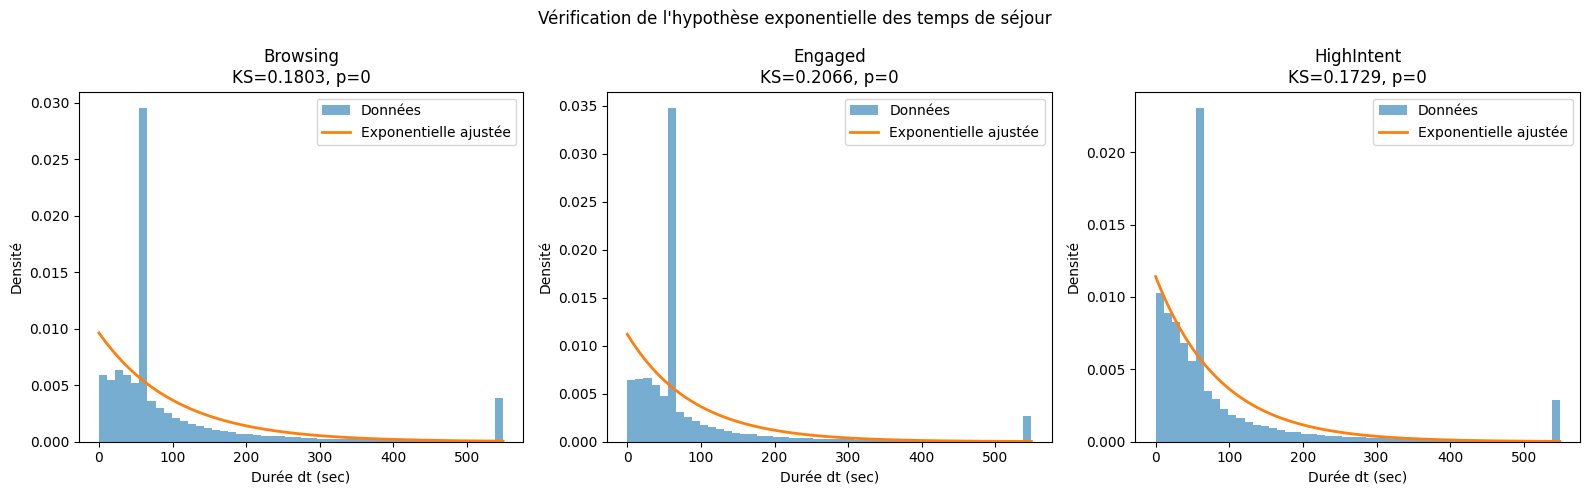


=== KS Test Exponentiel ===
        State    Mean_sec  Lambda_per_sec   KS_stat  p_value
0    Browsing  103.892950        0.009625  0.180346      0.0
1     Engaged   89.403166        0.011185  0.206587      0.0
2  HighIntent   87.661218        0.011408  0.172885      0.0


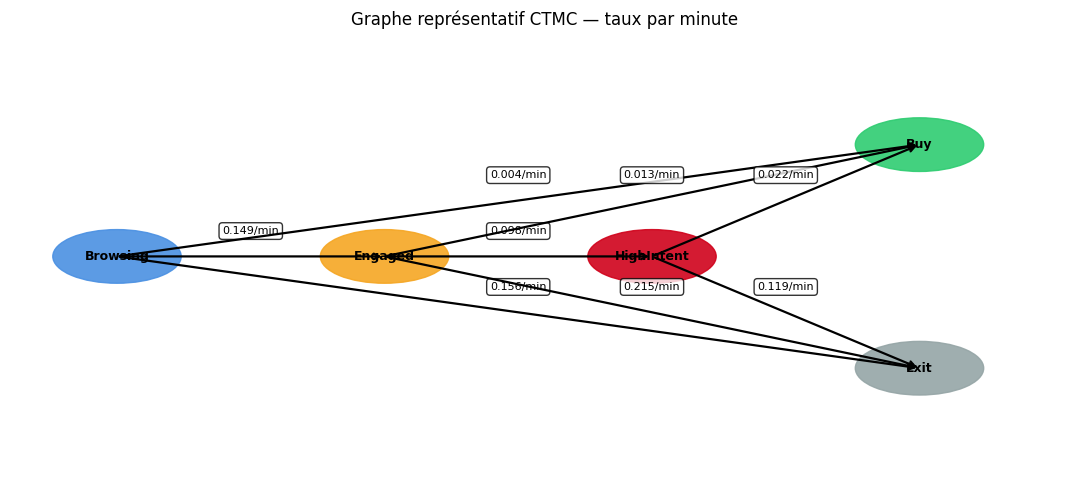


Toutes les visualisations sont sauvegardées dans outputs_ch2_ctmc/figures
Tous les fichiers CSV sont sauvegardés dans outputs_ch2_ctmc/csv


In [2]:
# ============================================================
# CHAPITRE 2 — CTMC YOOCHOOSE COMPLET + VISUALISATIONS
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.linalg import expm
from scipy import stats

# ============================================================
# 0) PATHS GOOGLE DRIVE
# ============================================================

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"
BUYS_PATH   = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

# ============================================================
# 1) PARAMÈTRES
# ============================================================

N_SESSIONS = 100000
RANDOM_SEED = 42

STATE_NAMES = ["Browsing", "Engaged", "HighIntent", "Buy", "Exit"]
TRANSIENT = ["Browsing", "Engaged", "HighIntent"]
ABSORBING = ["Buy", "Exit"]

B, E, H, BUY, EXIT = STATE_NAMES

os.makedirs("outputs_ch2_ctmc/csv", exist_ok=True)
os.makedirs("outputs_ch2_ctmc/figures", exist_ok=True)

# ============================================================
# 2) FONCTION ÉTAT
# ============================================================

def state_from_k(k):
    if k <= 2:
        return "Browsing"
    elif k <= 5:
        return "Engaged"
    else:
        return "HighIntent"

# ============================================================
# 3) LOAD BUYS
# ============================================================

print("Chargement buys...")

buys = pd.read_csv(
    BUYS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "price", "qty"],
    usecols=[0, 1],
    dtype={"session_id": "int64"},
    low_memory=False
)

buys["timestamp"] = pd.to_datetime(buys["timestamp"], errors="coerce", utc=True)
buys = buys.dropna(subset=["timestamp"])

buy_sessions_global = set(buys["session_id"].unique())

print("Sessions avec achat globales:", len(buy_sessions_global))

# ============================================================
# 4) LOAD CLICKS
# ============================================================

print("\nChargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

clicks["timestamp"] = pd.to_datetime(clicks["timestamp"], errors="coerce", utc=True)
clicks = clicks.dropna(subset=["timestamp"])

print("Clicks original:", clicks.shape)

# ============================================================
# 5) SAMPLING PAR SESSIONS
# ============================================================

all_sessions = clicks["session_id"].unique()

if N_SESSIONS and N_SESSIONS < len(all_sessions):
    rng = np.random.default_rng(RANDOM_SEED)
    sampled_sessions = rng.choice(all_sessions, size=N_SESSIONS, replace=False)
    sampled_sessions = set(sampled_sessions)

    clicks = clicks[clicks["session_id"].isin(sampled_sessions)]
    buys = buys[buys["session_id"].isin(sampled_sessions)]

    print("Sampling ON:", N_SESSIONS, "sessions")
else:
    sampled_sessions = set(all_sessions)
    print("Sampling OFF")

buy_sessions = set(buys["session_id"].unique())

print("Clicks utilisées:", clicks.shape)
print("Sessions utilisées:", clicks["session_id"].nunique())
print("Buys utilisées:", buys.shape)
print("Sessions avec achat dans sample:", len(buy_sessions))

# ============================================================
# 6) CONSTRUCTION DES ÉTATS ET DURÉES dt
# ============================================================

clicks = clicks.sort_values(["session_id", "timestamp"])

clicks["k"] = clicks.groupby("session_id").cumcount() + 1
clicks["state"] = clicks["k"].apply(state_from_k)

clicks["next_ts"] = clicks.groupby("session_id")["timestamp"].shift(-1)
clicks["dt"] = (clicks["next_ts"] - clicks["timestamp"]).dt.total_seconds()

valid_dt = clicks["dt"].dropna()

median_dt = float(valid_dt.median())
p95_dt = float(valid_dt.quantile(0.95))

default_last_dt = min(median_dt, p95_dt)

clicks["dt"] = clicks["dt"].fillna(default_last_dt)
clicks["dt"] = clicks["dt"].clip(lower=0.0, upper=p95_dt)

print("\nMedian dt:", round(median_dt, 3))
print("p95 dt:", round(p95_dt, 3))
print("default_last_dt:", round(default_last_dt, 3))

# ============================================================
# 7) COMPTAGE DES TRANSITIONS
# ============================================================

clicks["next_state"] = clicks.groupby("session_id")["state"].shift(-1)

transitions = clicks.dropna(subset=["next_state"])

N_tt = pd.crosstab(
    transitions["state"],
    transitions["next_state"]
).reindex(
    index=TRANSIENT,
    columns=TRANSIENT,
    fill_value=0
)

last_clicks = clicks.groupby("session_id").tail(1).copy()

last_clicks["absorb"] = np.where(
    last_clicks["session_id"].isin(buy_sessions),
    "Buy",
    "Exit"
)

N_abs = pd.crosstab(
    last_clicks["state"],
    last_clicks["absorb"]
).reindex(
    index=TRANSIENT,
    columns=ABSORBING,
    fill_value=0
)

N_full = pd.DataFrame(
    0.0,
    index=STATE_NAMES,
    columns=STATE_NAMES
)

for i in TRANSIENT:
    for j in TRANSIENT:
        N_full.loc[i, j] = float(N_tt.loc[i, j])
    for j in ABSORBING:
        N_full.loc[i, j] = float(N_abs.loc[i, j])

print("\n=== Matrice des transitions N ===")
print(N_full)

# ============================================================
# 8) TEMPS TOTAL PAR ÉTAT
# ============================================================

T = clicks.groupby("state")["dt"].sum().reindex(TRANSIENT, fill_value=0.0)

print("\n=== Temps total T_i en secondes ===")
print(T)

# ============================================================
# 9) MATRICE GÉNÉRATRICE Q
# ============================================================

Q_df = pd.DataFrame(
    0.0,
    index=STATE_NAMES,
    columns=STATE_NAMES
)

for i in TRANSIENT:
    Ti = float(T.loc[i])

    if Ti <= 0:
        raise ValueError(f"T[{i}] = 0 impossible d'estimer Q")

    for j in STATE_NAMES:
        if j != i:
            Q_df.loc[i, j] = N_full.loc[i, j] / Ti

    Q_df.loc[i, i] = -Q_df.loc[i, [s for s in STATE_NAMES if s != i]].sum()

Q_df.loc["Buy", :] = 0.0
Q_df.loc["Exit", :] = 0.0

Q_mat = Q_df.values.astype(float)

print("\n=== Matrice génératrice Q par seconde ===")
print(Q_df)

print("\n=== Matrice génératrice Q par minute ===")
print((Q_df * 60).round(6))

# ============================================================
# 10) VALIDATION CTMC
# ============================================================

print("\n=== Validation CTMC : somme des lignes de Q ===")
row_sums = Q_df.sum(axis=1)
print(row_sums)

assert np.allclose(row_sums.values, 0.0, atol=1e-10), "Erreur : les lignes de Q ne somment pas à 0"

print("Validation OK : Q est une matrice génératrice valide.")

# ============================================================
# 11) TEMPS MOYEN DE SÉJOUR
# ============================================================

out_rates = -np.diag(Q_df.loc[TRANSIENT, TRANSIENT].values)
mean_dwell_sec = 1 / out_rates

dwell_df = pd.DataFrame({
    "State": TRANSIENT,
    "OutRate_per_sec": out_rates,
    "MeanDwell_sec": mean_dwell_sec,
    "MeanDwell_min": mean_dwell_sec / 60
})

print("\n=== Temps moyen de séjour ===")
print(dwell_df)

# ============================================================
# 12) CHAÎNE EMBEDDED
# ============================================================

embedded = pd.DataFrame(
    0.0,
    index=TRANSIENT,
    columns=[s for s in STATE_NAMES]
)

for i in TRANSIENT:
    out_rate = -Q_df.loc[i, i]
    embedded.loc[i, :] = Q_df.loc[i, :] / out_rate
    embedded.loc[i, i] = 0.0

print("\n=== Probabilités de saut Embedded Chain ===")
print(embedded.round(6))

# ============================================================
# 13) P(t) = expm(Qt)
# ============================================================

print("\n=== Probabilités futures P(t) ===")

P_t_results = {}

for label, t in {"1_min": 60, "5_min": 300, "10_min": 600}.items():
    P_t = expm(Q_mat * t)
    P_t_df = pd.DataFrame(P_t, index=STATE_NAMES, columns=STATE_NAMES)
    P_t_results[label] = P_t_df

    print(f"\nP(t) = {label}")
    print(P_t_df.round(4))

# ============================================================
# 14) TEMPS MOYEN AVANT ABSORPTION
# ============================================================

Q_T = Q_df.loc[TRANSIENT, TRANSIENT].values
R_T = Q_df.loc[TRANSIENT, ABSORBING].values

N_ctmc = np.linalg.inv(-Q_T)

t_abs = N_ctmc @ np.ones(len(TRANSIENT))

N_ctmc_df = pd.DataFrame(
    N_ctmc,
    index=TRANSIENT,
    columns=TRANSIENT
)

t_abs_df = pd.DataFrame({
    "State": TRANSIENT,
    "MeanTimeAbsorption_sec": t_abs,
    "MeanTimeAbsorption_min": t_abs / 60
})

print("\n=== Matrice fondamentale CTMC N = (-Q_T)^-1 ===")
print(N_ctmc_df.round(4))

print("\n=== Temps moyen avant absorption ===")
print(t_abs_df.round(4))

# ============================================================
# 15) PROBABILITÉS D’ABSORPTION BUY / EXIT
# ============================================================

B_abs = N_ctmc @ R_T

B_abs_df = pd.DataFrame(
    B_abs,
    index=TRANSIENT,
    columns=ABSORBING
)

print("\n=== Probabilités d'absorption Buy / Exit ===")
print(B_abs_df.round(6))

print("\nRésumé:")
for st in TRANSIENT:
    print(
        f"{st}: P(Buy)={B_abs_df.loc[st,'Buy']:.4f}, "
        f"P(Exit)={B_abs_df.loc[st,'Exit']:.4f}, "
        f"Somme={B_abs_df.loc[st].sum():.4f}"
    )

# ============================================================
# 16) SAUVEGARDE CSV
# ============================================================

N_full.to_csv("outputs_ch2_ctmc/csv/transition_counts_N.csv")
T.to_csv("outputs_ch2_ctmc/csv/total_times_T.csv")
Q_df.to_csv("outputs_ch2_ctmc/csv/generator_Q_per_second.csv")
(Q_df * 60).to_csv("outputs_ch2_ctmc/csv/generator_Q_per_minute.csv")
embedded.to_csv("outputs_ch2_ctmc/csv/embedded_jump_probabilities.csv")
dwell_df.to_csv("outputs_ch2_ctmc/csv/mean_dwell_times.csv", index=False)
N_ctmc_df.to_csv("outputs_ch2_ctmc/csv/fundamental_matrix_ctmc.csv")
B_abs_df.to_csv("outputs_ch2_ctmc/csv/absorption_probabilities_ctmc.csv")
t_abs_df.to_csv("outputs_ch2_ctmc/csv/mean_time_absorption.csv", index=False)

for label, df in P_t_results.items():
    df.to_csv(f"outputs_ch2_ctmc/csv/P_t_{label}.csv")

print("\nCSV sauvegardés.")

# ============================================================
# 17) VISUALISATION 1 — HEATMAP Q PAR MINUTE
# ============================================================

plt.figure(figsize=(9, 6))

sns.heatmap(
    Q_df * 60,
    annot=True,
    fmt=".4f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice génératrice Q par minute — CTMC")
plt.xlabel("État destination")
plt.ylabel("État source")
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/heatmap_Q_per_minute.png", dpi=150)
plt.show()

# ============================================================
# 18) VISUALISATION 2 — TEMPS MOYEN DE SÉJOUR
# ============================================================

plt.figure(figsize=(7, 5))

sns.barplot(
    data=dwell_df,
    x="State",
    y="MeanDwell_min"
)

plt.title("Temps moyen de séjour par état")
plt.xlabel("État")
plt.ylabel("Temps moyen (minutes)")
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/mean_dwell_times.png", dpi=150)
plt.show()

# ============================================================
# 19) VISUALISATION 3 — ABSORPTION BUY / EXIT
# ============================================================

B_abs_df.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Probabilités finales d'absorption : Buy vs Exit")
plt.xlabel("État initial")
plt.ylabel("Probabilité")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/absorption_probabilities.png", dpi=150)
plt.show()

# ============================================================
# 20) VISUALISATION 4 — ÉVOLUTION TEMPORELLE DEPUIS BROWSING
# ============================================================

times_sec = np.linspace(0, 1200, 300)

probs_from_browsing = []

for t in times_sec:
    P_t = expm(Q_mat * t)
    probs_from_browsing.append(P_t[STATE_NAMES.index("Browsing"), :])

probs_from_browsing_df = pd.DataFrame(
    probs_from_browsing,
    columns=STATE_NAMES,
    index=times_sec / 60
)

plt.figure(figsize=(10, 6))

for state in STATE_NAMES:
    plt.plot(
        probs_from_browsing_df.index,
        probs_from_browsing_df[state],
        label=state
    )

plt.title("Évolution temporelle des probabilités depuis Browsing")
plt.xlabel("Temps (minutes)")
plt.ylabel("Probabilité")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/evolution_from_browsing.png", dpi=150)
plt.show()

# ============================================================
# 21) VISUALISATION 5 — ÉVOLUTION TEMPORELLE DEPUIS HIGHINTENT
# ============================================================

probs_from_high = []

for t in times_sec:
    P_t = expm(Q_mat * t)
    probs_from_high.append(P_t[STATE_NAMES.index("HighIntent"), :])

probs_from_high_df = pd.DataFrame(
    probs_from_high,
    columns=STATE_NAMES,
    index=times_sec / 60
)

plt.figure(figsize=(10, 6))

for state in STATE_NAMES:
    plt.plot(
        probs_from_high_df.index,
        probs_from_high_df[state],
        label=state
    )

plt.title("Évolution temporelle des probabilités depuis HighIntent")
plt.xlabel("Temps (minutes)")
plt.ylabel("Probabilité")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/evolution_from_highintent.png", dpi=150)
plt.show()

# ============================================================
# 22) VISUALISATION 6 — TEST LOI EXPONENTIELLE
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ks_results = []

for idx, state in enumerate(TRANSIENT):
    dur = clicks[clicks["state"] == state]["dt"].dropna()
    dur = dur[dur > 0]

    mean_dur = dur.mean()
    lam = 1 / mean_dur

    ks_stat, p_val = stats.kstest(dur, "expon", args=(0, mean_dur))

    ks_results.append({
        "State": state,
        "Mean_sec": mean_dur,
        "Lambda_per_sec": lam,
        "KS_stat": ks_stat,
        "p_value": p_val
    })

    dur_plot = dur.clip(upper=dur.quantile(0.99))

    axes[idx].hist(
        dur_plot,
        bins=50,
        density=True,
        alpha=0.6,
        label="Données"
    )

    x = np.linspace(0, dur_plot.max(), 300)
    axes[idx].plot(
        x,
        lam * np.exp(-lam * x),
        linewidth=2,
        label="Exponentielle ajustée"
    )

    axes[idx].set_title(f"{state}\nKS={ks_stat:.4f}, p={p_val:.4g}")
    axes[idx].set_xlabel("Durée dt (sec)")
    axes[idx].set_ylabel("Densité")
    axes[idx].legend()

plt.suptitle("Vérification de l'hypothèse exponentielle des temps de séjour")
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/exponential_fit_by_state.png", dpi=150)
plt.show()

ks_df = pd.DataFrame(ks_results)
ks_df.to_csv("outputs_ch2_ctmc/csv/ks_exponential_tests.csv", index=False)

print("\n=== KS Test Exponentiel ===")
print(ks_df)

# ============================================================
# 23) GRAPHE REPRÉSENTATIF SIMPLE
# ============================================================

plt.figure(figsize=(11, 5))
ax = plt.gca()
ax.axis("off")

positions = {
    "Browsing": (0.1, 0.5),
    "Engaged": (0.35, 0.5),
    "HighIntent": (0.6, 0.5),
    "Buy": (0.85, 0.75),
    "Exit": (0.85, 0.25)
}

colors = {
    "Browsing": "#4A90E2",
    "Engaged": "#F5A623",
    "HighIntent": "#D0021B",
    "Buy": "#2ECC71",
    "Exit": "#95A5A6"
}

for state, (x, y) in positions.items():
    circle = plt.Circle((x, y), 0.06, color=colors[state], alpha=0.9)
    ax.add_patch(circle)
    ax.text(x, y, state, ha="center", va="center", fontsize=9, fontweight="bold")

for src in TRANSIENT:
    for dst in STATE_NAMES:
        rate = Q_df.loc[src, dst]
        if src != dst and rate > 1e-8:
            x1, y1 = positions[src]
            x2, y2 = positions[dst]

            ax.annotate(
                "",
                xy=(x2, y2),
                xytext=(x1, y1),
                arrowprops=dict(
                    arrowstyle="->",
                    lw=1.6,
                    color="black"
                )
            )

            ax.text(
                (x1+x2)/2,
                (y1+y2)/2 + 0.05,
                f"{rate*60:.3f}/min",
                ha="center",
                fontsize=8,
                bbox=dict(boxstyle="round", fc="white", alpha=0.8)
            )

plt.title("Graphe représentatif CTMC — taux par minute")
plt.tight_layout()
plt.savefig("outputs_ch2_ctmc/figures/ctmc_graph.png", dpi=150)
plt.show()

print("\nToutes les visualisations sont sauvegardées dans outputs_ch2_ctmc/figures")
print("Tous les fichiers CSV sont sauvegardés dans outputs_ch2_ctmc/csv")

### **Interprétation Chapitre 2 — CTMC**

Le modèle CTMC prolonge le Chapitre 1 en ajoutant la dimension temporelle réelle. Au lieu d’analyser seulement les transitions en nombre de clics, on mesure ici les taux de passage par seconde/minute entre les états comportementaux.

1. Validation de la matrice génératrice Q

La somme des lignes de Q est proche de zéro :

Browsing ≈ 0
Engaged ≈ 0
HighIntent = 0
Buy = 0
Exit = 0

Donc la matrice Q est bien une matrice génératrice valide pour une chaîne de Markov à temps continu.

2. Temps moyen de séjour
État	Temps moyen
Browsing	3.23 min
Engaged	3.07 min
HighIntent	7.14 min

L’état HighIntent possède le temps moyen de séjour le plus élevé. Cela signifie que les utilisateurs ayant une forte intention d’achat restent plus longtemps dans une phase d’hésitation avant de décider d’acheter ou de quitter.

3. Probabilités de saut

Depuis Browsing :

48.20% → Engaged
1.41% → Buy
50.39% → Exit

Depuis Engaged :

30.10% → HighIntent
4.07% → Buy
65.83% → Exit

Depuis HighIntent :

15.40% → Buy
84.60% → Exit

Cela montre que l’abandon reste dominant dans tous les états. Même en HighIntent, la majorité des utilisateurs quittent sans achat.

4. Évolution temporelle P(t)

Après 1 minute depuis Browsing :

73.36% restent Browsing
14.75% sont déjà Exit
0.46% Buy

Après 5 minutes :

56.07% Exit
2.30% Buy

Après 10 minutes :

79.32% Exit
3.88% Buy

Donc l’abandon augmente rapidement avec le temps. La fenêtre d’intervention marketing doit être précoce, surtout avant 5 minutes.

5. Temps moyen avant absorption
État initial	Temps avant Buy/Exit
Browsing	5.74 min
Engaged	5.22 min
HighIntent	7.14 min

Cela signifie que depuis Browsing ou Engaged, une session se termine en moyenne après environ 5 à 6 minutes. Depuis HighIntent, la décision est plus longue.

6. Probabilités finales d’absorption
État initial	P(Buy)	P(Exit)
Browsing	5.61%	94.39%
Engaged	8.71%	91.29%
HighIntent	15.40%	84.60%

La probabilité d’achat augmente avec l’engagement :

Browsing < Engaged < HighIntent

C’est cohérent avec le tunnel de conversion.

7. Test de la loi exponentielle

Le test KS donne :

p-value = 0.0

Donc l’hypothèse exponentielle stricte est rejetée statistiquement. Mais comme le dataset est très grand, le test KS est très sensible. Il faut donc conclure prudemment :

La loi exponentielle constitue une approximation utile pour construire une CTMC, mais les durées réelles de navigation présentent des écarts liés à l’hétérogénéité des comportements utilisateurs.